# Disciplina: Ciência de Dados
## Lab 04 - EDA e Estatística Descritiva

**Orientações para o aluno:**
1. Leia atentamente o enunciado de cada questão.
2. Utilize as bibliotecas `pandas`, `numpy`, `matplotlib` e `seaborn` para as análises.
3. O objetivo deste lab é aplicar conceitos de Medidas de Tendência Central, Medidas de Dispersão e Visualização de Dados para extrair insights de um dataset.

### 🔹 Questão 1: Preparação do Ambiente e Carga de Dados

**Enunciado:** Vamos utilizar o dataset `tips` (gorjetas), disponível nativamente na biblioteca Seaborn, para nossa análise.

**Requisitos:**
- Carregar o dataset utilizando `sns.load_dataset('tips')`.
- Exibir as 5 primeiras linhas.
- Verificar o tipo de cada variável e se existem valores nulos utilizando `.info()`.

In [1]:
# QUESTÃO 1 — Preparação do Ambiente e Carga de Dados

# Importação das bibliotecas necessárias para toda a análise
import pandas as pd       # Manipulação de dados tabulares
import numpy as np        # Operações numéricas
import matplotlib.pyplot as plt  # Criação de gráficos base
import seaborn as sns     # Visualizações estatísticas de alto nível

# Configuração visual: aplica um estilo mais limpo aos gráficos
sns.set_theme(style='whitegrid')

# 1.1 — Carregamento do dataset
# O dataset 'tips' registra informações de gorjetas em um
# restaurante: valor da conta, gorjeta, sexo do pagador,
# se fumante, dia da semana, período (almoço/jantar) e
# tamanho do grupo.
df = sns.load_dataset('tips')

# 1.2 — Exibe as 5 primeiras linhas para uma visão geral
print('=== Primeiras 5 linhas do dataset ===')
print(df.head())

# 1.3 — Informações gerais: tipos de dados e valores nulos
# .info() mostra:
#   - Número de linhas e colunas
#   - Tipo de dado de cada coluna (int64, float64, object, category)
#   - Contagem de valores não-nulos (se for menor que o total,
#     há valores faltando)
print('\n=== Informações do DataFrame ===')
df.info()

=== Primeiras 5 linhas do dataset ===
   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4

=== Informações do DataFrame ===
<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


### 🔹 Questão 2: Medidas de Tendência Central

**Enunciado:** Analise a variável `total_bill` (valor total da conta) para entender o gasto médio dos clientes.

**Requisitos:**
- Calcular a Média, Mediana e Moda da coluna `total_bill`.

In [2]:
# QUESTÃO 2 — Medidas de Tendência Central
# As medidas de tendência central indicam um valor "típico"
# ou "representativo" de um conjunto de dados.

# 2.1 — MÉDIA: soma de todos os valores dividida pela quantidade.
# Sensível a valores extremos (outliers).
media = df['total_bill'].mean()

# 2.2 — MEDIANA: valor central quando os dados estão ordenados.
# Mais robusta a outliers que a média.
# Se média > mediana, a distribuição tende a ser assimétrica
# à direita (cauda longa nos valores altos).
mediana = df['total_bill'].median()

# 2.3 — MODA: valor que aparece com maior frequência.
# Útil para variáveis categóricas; em variáveis contínuas
# pode haver múltiplas modas ou nenhuma muito evidente.
# .mode() retorna uma Series, então pegamos o primeiro valor.
moda = df['total_bill'].mode()[0]

# Exibição formatada dos resultados
print('=== Medidas de Tendência Central — total_bill ===')
print(f'Média  : R$ {media:.2f}')
print(f'Mediana: R$ {mediana:.2f}')
print(f'Moda   : R$ {moda:.2f}')

# Interpretação automática da assimetria
print('\n--- Interpretação ---')
if media > mediana:
    print('Média > Mediana → distribuição assimétrica à direita.')
    print('Existem contas muito altas puxando a média para cima.')
elif media < mediana:
    print('Média < Mediana → distribuição assimétrica à esquerda.')
else:
    print('Média ≈ Mediana → distribuição aproximadamente simétrica.')

=== Medidas de Tendência Central — total_bill ===
Média  : R$ 19.79
Mediana: R$ 17.80
Moda   : R$ 13.42

--- Interpretação ---
Média > Mediana → distribuição assimétrica à direita.
Existem contas muito altas puxando a média para cima.


### 🔹 Questão 3: Medidas de Dispersão

**Enunciado:** O valor das contas varia muito? Calcule a variabilidade dos gastos.

**Requisitos:**
- Calcular o Desvio Padrão e a Variância de `total_bill`.
- Obter o resumo estatístico completo para comparar os quartis.

In [3]:
# QUESTÃO 3 — Medidas de Dispersão
# As medidas de dispersão quantificam o quanto os dados se
# afastam do valor central. Uma dispersão alta indica
# grande variabilidade nos gastos.

# 3.1 — VARIÂNCIA: média dos quadrados dos desvios em relação
# à média. Está na unidade ao quadrado (ex.: dólares²),
# o que dificulta a interpretação direta.
# ddof=1 → divisão por (n-1), estimativa amostral (padrão).
variancia = df['total_bill'].var()

# 3.2 — DESVIO PADRÃO: raiz quadrada da variância.
# Está na mesma unidade dos dados, sendo mais interpretável.
# Ex.: desvio de $8 significa que os gastos tipicamente
# variam ±$8 em torno da média.
desvio_padrao = df['total_bill'].std()

print('=== Medidas de Dispersão — total_bill ===')
print(f'Variância   : {variancia:.2f}')
print(f'Desvio Padrão: {desvio_padrao:.2f}')

# 3.3 — RESUMO ESTATÍSTICO COMPLETO
# .describe() retorna: contagem, média, desvio padrão,
# mínimo, quartis (Q1=25%, Q2=50%=mediana, Q3=75%) e máximo.
# A diferença Q3 - Q1 é o IQR (Intervalo Interquartil),
# que representa a dispersão dos 50% centrais dos dados.
print('\n=== Resumo Estatístico Completo ===')
print(df['total_bill'].describe())

# Calculando o IQR manualmente para evidenciar o conceito
q1 = df['total_bill'].quantile(0.25)
q3 = df['total_bill'].quantile(0.75)
iqr = q3 - q1

print(f'\nIQR (Q3 - Q1) = {iqr:.2f}')
print('O IQR mostra a amplitude dos 50% centrais dos dados,')
print('sendo menos sensível a outliers que o desvio padrão.')

=== Medidas de Dispersão — total_bill ===
Variância   : 79.25
Desvio Padrão: 8.90

=== Resumo Estatístico Completo ===
count    244.000000
mean      19.785943
std        8.902412
min        3.070000
25%       13.347500
50%       17.795000
75%       24.127500
max       50.810000
Name: total_bill, dtype: float64

IQR (Q3 - Q1) = 10.78
O IQR mostra a amplitude dos 50% centrais dos dados,
sendo menos sensível a outliers que o desvio padrão.


### 🔹 Questão 4: Visualização e Identificação de Outliers

**Enunciado:** A visualização gráfica é essencial na EDA. Vamos verificar a distribuição da conta total e identificar possíveis valores atípicos.

**Requisitos:**
- Criar um Boxplot para a coluna `total_bill`.
- Criar um Histograma com KDE para ver a forma da distribuição dos gastos.

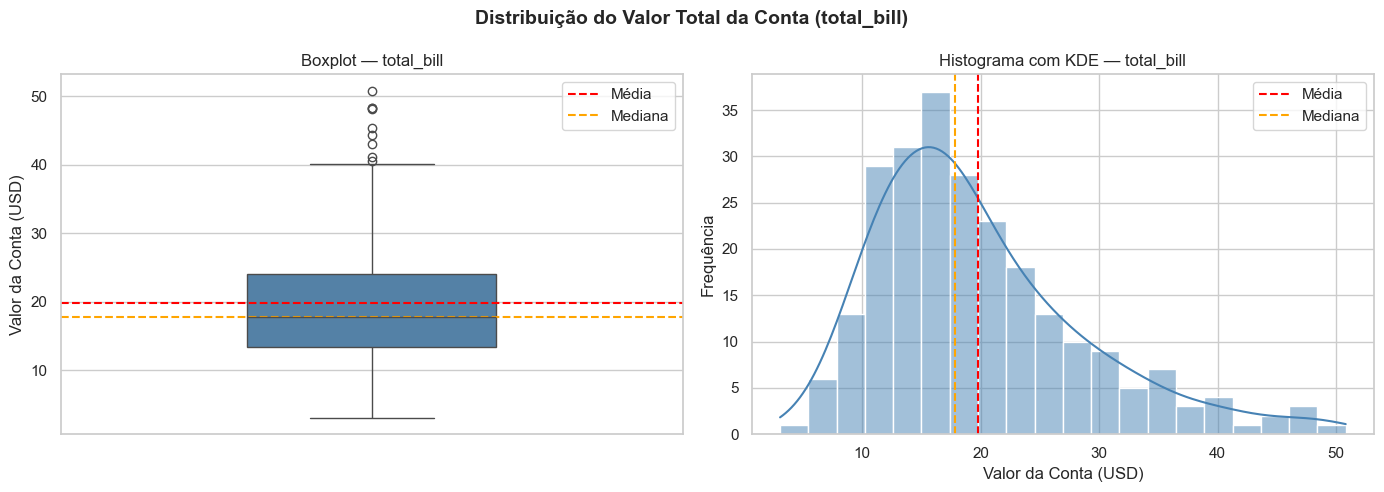

Limite inferior para outliers: -2.82
Limite superior para outliers: 40.30
Número de outliers encontrados: 9

Registros considerados outliers:
     total_bill    tip  size
59        48.27   6.73     4
102       44.30   2.50     3
142       41.19   5.00     5
156       48.17   5.00     6
170       50.81  10.00     3
182       45.35   3.50     3
184       40.55   3.00     2
197       43.11   5.00     4
212       48.33   9.00     4


In [4]:
# QUESTÃO 4 — Visualização e Identificação de Outliers

# Criamos uma figura com dois subplots lado a lado
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Distribuição do Valor Total da Conta (total_bill)',
             fontsize=14, fontweight='bold')

# 4.1 — BOXPLOT (Diagrama de Caixa)
# Exibe os quartis (Q1, mediana, Q3) como a caixa central.
# Os "bigodes" (whiskers) se estendem até 1,5 × IQR.
# Pontos além dos bigodes são outliers potenciais.
sns.boxplot(
    y=df['total_bill'],
    ax=axes[0],
    color='steelblue',
    width=0.4
)
axes[0].set_title('Boxplot — total_bill')
axes[0].set_ylabel('Valor da Conta (USD)')
# Adiciona linhas de referência para média e mediana
axes[0].axhline(df['total_bill'].mean(),   color='red',    linestyle='--', label='Média')
axes[0].axhline(df['total_bill'].median(), color='orange', linestyle='--', label='Mediana')
axes[0].legend()

# 4.2 — HISTOGRAMA com KDE (Kernel Density Estimation)
# O histograma mostra a frequência de cada faixa de valores.
# A curva KDE suaviza o histograma e permite visualizar
# a "forma" da distribuição (simétrica, assimétrica, bimodal).
sns.histplot(
    df['total_bill'],
    bins=20,       # número de barras do histograma
    kde=True,      # sobrepõe a curva de densidade
    ax=axes[1],
    color='steelblue',
    edgecolor='white'
)
# Linhas verticais indicando média e mediana
axes[1].axvline(df['total_bill'].mean(),   color='red',    linestyle='--', label='Média')
axes[1].axvline(df['total_bill'].median(), color='orange', linestyle='--', label='Mediana')
axes[1].set_title('Histograma com KDE — total_bill')
axes[1].set_xlabel('Valor da Conta (USD)')
axes[1].set_ylabel('Frequência')
axes[1].legend()

plt.tight_layout()
plt.show()

# Identificação numérica dos outliers usando a regra do IQR
# Um ponto é outlier se estiver abaixo de Q1 - 1,5*IQR
# ou acima de Q3 + 1,5*IQR.
q1  = df['total_bill'].quantile(0.25)
q3  = df['total_bill'].quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

outliers = df[(df['total_bill'] < limite_inferior) |
              (df['total_bill'] > limite_superior)]

print(f'Limite inferior para outliers: {limite_inferior:.2f}')
print(f'Limite superior para outliers: {limite_superior:.2f}')
print(f'Número de outliers encontrados: {len(outliers)}')
print('\nRegistros considerados outliers:')
print(outliers[['total_bill', 'tip', 'size']].to_string())

### 🔹 Questão 5: Análise de Correlação Bivariada

**Enunciado:** Existe relação entre o valor da conta (`total_bill`) e o valor da gorjeta (`tip`)?

**Requisitos:**
- Calcular a correlação de Pearson entre as duas variáveis.
- Plotar um gráfico de dispersão com a reta de regressão.

=== Correlação de Pearson: total_bill × tip ===
r = 0.6757
→ Correlação positiva e forte.
  Contas mais altas tendem a gerar gorjetas maiores.


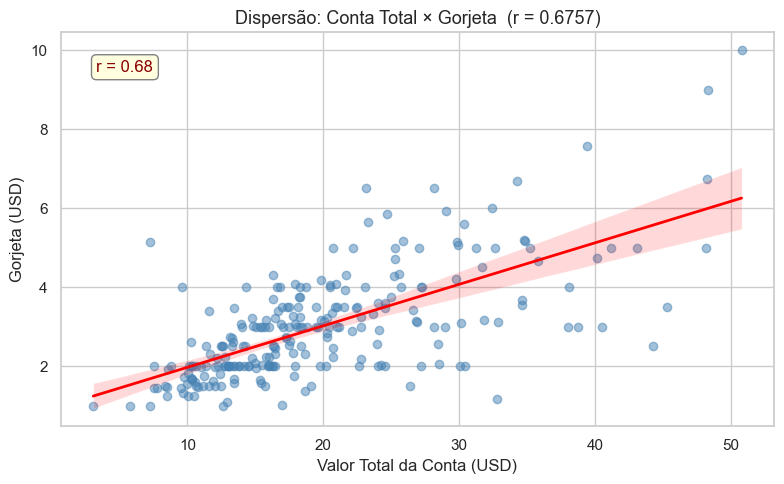

In [5]:
# QUESTÃO 5 — Análise de Correlação Bivariada

# 5.1 — CORRELAÇÃO DE PEARSON
# Mede a força e a direção de uma relação LINEAR entre
# duas variáveis numéricas.
# Varia de -1 a +1:
#   +1 → correlação positiva perfeita
#    0 → sem correlação linear
#   -1 → correlação negativa perfeita
# Referência prática (valor absoluto):
#   0.0 – 0.2 → muito fraca
#   0.2 – 0.4 → fraca
#   0.4 – 0.6 → moderada
#   0.6 – 0.8 → forte
#   0.8 – 1.0 → muito forte
correlacao = df['total_bill'].corr(df['tip'])

print('=== Correlação de Pearson: total_bill × tip ===')
print(f'r = {correlacao:.4f}')

# Interpretação automática
abs_r = abs(correlacao)
if abs_r >= 0.8:
    forca = 'muito forte'
elif abs_r >= 0.6:
    forca = 'forte'
elif abs_r >= 0.4:
    forca = 'moderada'
elif abs_r >= 0.2:
    forca = 'fraca'
else:
    forca = 'muito fraca'

direcao = 'positiva' if correlacao > 0 else 'negativa'
print(f'→ Correlação {direcao} e {forca}.')
print('  Contas mais altas tendem a gerar gorjetas maiores.')

# 5.2 — GRÁFICO DE DISPERSÃO COM RETA DE REGRESSÃO
# O scatterplot mostra cada observação como um ponto no plano.
# A reta de regressão (método dos mínimos quadrados) resume
# a tendência linear entre as variáveis.
plt.figure(figsize=(8, 5))

sns.regplot(
    data=df,
    x='total_bill',
    y='tip',
    scatter_kws={'alpha': 0.5, 'color': 'steelblue'},  # pontos semitransparentes
    line_kws={'color': 'red', 'linewidth': 2},          # reta de regressão vermelha
    ci=95   # faixa de confiança de 95% ao redor da reta
)

plt.title(f'Dispersão: Conta Total × Gorjeta  (r = {correlacao:.4f})',
          fontsize=13)
plt.xlabel('Valor Total da Conta (USD)')
plt.ylabel('Gorjeta (USD)')

# Texto com o coeficiente de correlação dentro do gráfico
plt.annotate(
    f'r = {correlacao:.2f}',
    xy=(0.05, 0.90),
    xycoords='axes fraction',
    fontsize=12,
    color='darkred',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', edgecolor='gray')
)

plt.tight_layout()
plt.show()